# Phase 3 — Deep Learning & Neural Networks
## Notebook 05: CNNs & Edge Deployment (TensorFlow & TF Lite)

### Executive Overview & Edge Deployment Dominance
While PyTorch dominates cloud-based training for large foundation models, **TensorFlow and the TensorFlow Lite (TFLite) ecosystem are the undisputed industry leaders for on-device, mobile, and embedded edge AI**. Billions of Android smartphones, iOS apps, microcontrollers (Cortex-M), automotive ECUs, and Google Coral TPUs run inference via optimized TFLite flatbuffers (`.tflite`).

Deploying deep learning models to the edge requires addressing strict hardware constraints:
1. **DRAM Bandwidth Limits**: Memory bus access consumes orders of magnitude more energy than arithmetic compute.
2. **Compute Latency**: Real-time robotics and mobile computer vision demand sub-20ms inference without cloud round-trips.
3. **Storage Footprint**: Microcontrollers operate with kilobyte-scale flash storage.

```
+-----------------------------------------------------------------------------------+
|               TensorFlow Edge Optimization & Deployment Hierarchy                 |
+-----------------------------------------------------------------------------------+
| Training        | Keras 3 / TensorFlow 2.x (FP32 Model in RAM)                    |
| Architecture    | Depthwise-Separable Convolutions (MobileNetV2 Inverted Residual)|
| Compression     | Post-Training Quantization (PTQ) & Calibration Dataset          |
| Target Formats  | FP32 Flatbuffer ---> Dynamic Range INT8 ---> Full Integer INT8  |
| Runtime Engine  | TensorFlow Lite C++ Interpreter & XNNPACK Acceleration          |
| Edge Targets    | Mobile (Android/iOS), IoT (Raspberry Pi), Microcontrollers (MCU)|
+-----------------------------------------------------------------------------------+
```

In this notebook, we master Depthwise-Separable convolutions, build and train an edge-optimized vision model in Keras 3, and convert it through the full TFLite quantization spectrum: **FP32 $	o$ Dynamic Range $	o$ Full INT8 Quantization with Representative Dataset Calibration**.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Analyze Depthwise Separable Convolutions**: Understand the mathematical decomposition of standard convolutions into depthwise and pointwise stages, achieving an 85–90% reduction in computational FLOPs.
2. **Build Edge-Optimized Architectures in Keras**: Implement inverted residual bottleneck blocks with linear bottlenecks (`MobileNet` philosophy) using the Keras Functional API.
3. **Execute Post-Training Quantization (PTQ)**: Transform full-precision 32-bit floating point models into 8-bit integer formats using `tf.lite.TFLiteConverter`.
4. **Calibrate INT8 Quantization with Representative Data**: Implement calibration generators to compute dynamic range activation scales ($S$) and zero-points ($Z$).
5. **Benchmark Edge Inference with TFLite Interpreter**: Measure model disk footprint, inference latency (ms), and accuracy retention across FP32, Dynamic Range, and INT8 flatbuffers.


In [1]:
import sys
import os
import time
import platform
from typing import Dict, List, Tuple, Any, Generator

import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

# Suppress TF logs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

print(f"Python Platform:    {platform.python_implementation()} {platform.python_version()}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
print(f"NumPy Version:      {np.__version__}")


I0000 00:00:1794180386.614515     690 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794180386.655344     690 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794180387.964799     690 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Platform:    CPython 3.11.2
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
NumPy Version:      2.4.6


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    print(f"Global seed {seed} synchronized across NumPy and TensorFlow.")

configure_reproducibility(42)


Global seed 42 synchronized across NumPy and TensorFlow.


### Mathematical & Architectural Foundations

#### 1. Depthwise Separable Convolutions
A standard 2D convolution filters and combines inputs into a new set of outputs in one step. For an input feature map $D_F \times D_F \times M$ and output $D_F \times D_F \times N$ with kernel size $D_K \times D_K$:

$$\text{Standard Conv FLOPs} = D_K \cdot D_K \cdot M \cdot N \cdot D_F \cdot D_F$$

**Depthwise Separable Convolution** factorizes this operation into two disjoint steps:
1. **Depthwise Convolution**: Applies a single spatial convolutional filter per input channel ($M$ filters of size $D_K \times D_K \times 1$):
   $$\text{Depthwise FLOPs} = D_K \cdot D_K \cdot M \cdot D_F \cdot D_F$$
2. **Pointwise Convolution**: A $1 \times 1$ convolution that computes linear combinations of all channels:
   $$\text{Pointwise FLOPs} = 1 \cdot 1 \cdot M \cdot N \cdot D_F \cdot D_F$$

$$\text{Total Separable FLOPs} = D_K \cdot D_K \cdot M \cdot D_F \cdot D_F + M \cdot N \cdot D_F \cdot D_F$$

The computational reduction ratio is:

$$\text{Reduction Ratio} = \frac{D_K^2 \cdot M \cdot D_F^2 + M \cdot N \cdot D_F^2}{D_K^2 \cdot M \cdot N \cdot D_F^2} = \frac{1}{N} + \frac{1}{D_K^2}$$

For standard $3 \times 3$ kernels ($D_K = 3$):

$$\text{Reduction Ratio} \approx \frac{1}{9} \approx 11\% \implies \mathbf{89\% \text{ reduction in arithmetic compute!}}$$

#### 2. Uniform Affine Quantization Mathematics
Quantization maps 32-bit floating-point numbers $r \in [\alpha, \beta]$ to $b$-bit integers $q \in [q_{\min}, q_{\max}]$ (where for signed INT8, $q \in [-128, 127]$):

$$q = \text{round}\left( \frac{r}{S} \right) + Z$$

Where:
- **$S$ (Scale factor)**: A positive real scalar defining the step size:
  $$S = \frac{\beta - \alpha}{q_{\max} - q_{\min}}$$
- **$Z$ (Zero-point)**: An integer ensuring real-value zero maps exactly to an integer (crucial for zero-padded convolutions):
  $$Z = \text{round}\left( \frac{-\alpha}{S} \right) + q_{\min}$$

The real float value is dequantized via:
$$r \approx S \cdot (q - Z)$$


### 1. Geometric Vision Dataset Generation
We synthesize a multi-class vision dataset ($N=1500$ samples, $28 	imes 28 	imes 1$) with 3 classes (Square, Circle, Cross) along with random scaling and noise.


In [3]:
def create_vision_dataset(num_samples: int = 1500, img_size: int = 28) -> Tuple[np.ndarray, np.ndarray]:
    np.random.seed(42)
    images = np.zeros((num_samples, img_size, img_size, 1), dtype=np.float32)
    labels = np.zeros((num_samples,), dtype=np.int32)

    for i in range(num_samples):
        cls = i % 3
        labels[i] = cls
        img = np.zeros((img_size, img_size), dtype=np.float32)
        cx, cy = np.random.randint(img_size//4, 3*img_size//4, size=2)

        if cls == 0:  # Square
            hw = np.random.randint(4, 7)
            r0, r1 = max(0, cy - hw), min(img_size, cy + hw)
            c0, c1 = max(0, cx - hw), min(img_size, cx + hw)
            img[r0:r1, c0:c1] = 1.0
        elif cls == 1:  # Circle
            rad = np.random.randint(4, 7)
            yg, xg = np.ogrid[:img_size, :img_size]
            dist = (xg - cx)**2 + (yg - cy)**2
            img[dist <= rad**2] = 1.0
        else:  # Cross
            arm = np.random.randint(5, 8)
            for d in range(-arm, arm + 1):
                if 0 <= cy + d < img_size and 0 <= cx + d < img_size: img[cy + d, cx + d] = 1.0
                if 0 <= cy + d < img_size and 0 <= cx - d < img_size: img[cy + d, cx - d] = 1.0

        noise = np.random.normal(0, 0.15, size=img.shape).astype(np.float32)
        images[i, :, :, 0] = np.clip(img + noise, 0.0, 1.0)

    return images, labels

X_all, y_all = create_vision_dataset(1500, 28)
X_train, y_train = X_all[:1200], y_all[:1200]
X_val, y_val = X_all[1200:], y_all[1200:]

print(f"Generated Vision Dataset: {X_all.shape}, Dtype: {X_all.dtype}")
print(f"Train samples: {len(X_train)}, Validation samples: {len(X_val)}")


Generated Vision Dataset: (1500, 28, 28, 1), Dtype: float32
Train samples: 1200, Validation samples: 300


### 2. Depthwise-Separable CNN Architecture in Keras
We construct an edge-optimized CNN using `keras.layers.SeparableConv2D` and inverted residual bottleneck concepts:
1. Standard Conv2D stem for initial spatial representation.
2. Two Inverted Residual Bottleneck blocks using `DepthwiseConv2D` and Pointwise `Conv2D(1x1)` with residual addition.
3. `GlobalAveragePooling2D` to eliminate dense parameter count.
4. Final classification softmax head.


In [4]:
def inverted_residual_block(x: keras.KerasTensor, expansion: int, out_channels: int, stride: int = 1) -> keras.KerasTensor:
    """MobileNetV2 style inverted residual bottleneck block."""
    in_channels = x.shape[-1]
    identity = x

    # 1. Expansion phase (Pointwise 1x1)
    if expansion != 1:
        x = keras.layers.Conv2D(in_channels * expansion, kernel_size=1, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU(max_value=6.0)(x)

    # 2. Depthwise phase (3x3 spatial filter per channel)
    x = keras.layers.DepthwiseConv2D(kernel_size=3, strides=stride, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU(max_value=6.0)(x)

    # 3. Linear projection phase (Pointwise 1x1, no non-linearity)
    x = keras.layers.Conv2D(out_channels, kernel_size=1, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)

    # 4. Residual shortcut
    if stride == 1 and in_channels == out_channels:
        x = keras.layers.Add()([identity, x])

    return x

def build_edge_cnn(input_shape=(28, 28, 1), num_classes=3) -> keras.Model:
    inputs = keras.Input(shape=input_shape, name="input_image")
    
    # Initial stem
    x = keras.layers.Conv2D(16, kernel_size=3, strides=1, padding="same", use_bias=False)(inputs)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU(max_value=6.0)(x)

    # Inverted residual blocks
    x = inverted_residual_block(x, expansion=1, out_channels=16, stride=1)
    x = inverted_residual_block(x, expansion=4, out_channels=32, stride=2)  # 28x28 -> 14x14
    x = inverted_residual_block(x, expansion=4, out_channels=64, stride=2)  # 14x14 -> 7x7

    # Head
    x = keras.layers.GlobalAveragePooling2D()(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax", name="probabilities")(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="EdgeMobileCNN")

edge_model = build_edge_cnn()
print(f"Edge CNN Model instantiated with {edge_model.count_params():,} parameters.")


Edge CNN Model instantiated with 19,939 parameters.


### 3. Training & Evaluation of the Baseline FP32 Model
We compile and train `EdgeMobileCNN` using Adam optimizer with categorical crossentropy loss, and save the baseline Keras model.


In [5]:
edge_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training Edge CNN model...")
train_history = edge_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

# Evaluate baseline accuracy
val_loss, val_acc = edge_model.evaluate(X_val, y_val, verbose=0)
print(f"\nBaseline Keras FP32 Model - Validation Loss: {val_loss:.4f}, Accuracy: {val_acc*100:.2f}%")


Training Edge CNN model...


Epoch 1/10


 1/38 ━━━━━━━━━━━━━━━━━━━━ 2:07 3s/step - accuracy: 0.6562 - loss: 1.0078

 3/38 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7083 - loss: 0.9255

 5/38 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.7250 - loss: 0.8144

 7/38 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7545 - loss: 0.7473

... (204 outputs left out)

35/38 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 7.5699e-04

37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 1.0000 - loss: 7.3427e-04

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 1.0000 - loss: 7.3006e-04 - val_accuracy: 0.3333 - val_loss: 1.8458



Baseline Keras FP32 Model - Validation Loss: 1.8458, Accuracy: 33.33%


### Diagnostics & Edge Deployment Benchmarking: TFLite Quantization Suite
We convert the trained Keras model into three TFLite variants:
1. **Unquantized Float32 TFLite (`fp32.tflite`)**: Baseline flatbuffer with direct 32-bit floats.
2. **Dynamic Range Quantized (`dynamic_range.tflite`)**: Quantizes weights to INT8 post-training while computing activations dynamically in float32.
3. **Full Integer INT8 Quantized (`int8.tflite`)**: Quantizes both weights and activations to INT8 using a representative calibration dataset, enabling execution on integer-only hardware (microcontrollers, Coral Edge TPU).

We benchmark **Model Disk Footprint (KB)**, **Inference Latency (ms)**, and **Validation Accuracy**.


INFO:tensorflow:Assets written to: /tmp/tmp1duch743/assets


INFO:tensorflow:Assets written to: /tmp/tmp1duch743/assets


Saved artifact at '/tmp/tmp1duch743'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139374093879440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808763920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808762768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139374093878864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139374093877328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139374093878672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808762960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808765072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808764688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808764496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139372808763344: 

W0000 00:00:1794180409.491277     690 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794180409.491312     690 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794180409.491715     690 reader.cc:83] Reading SavedModel from: /tmp/tmp1duch743
I0000 00:00:1794180409.496632     690 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794180409.496649     690 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp1duch743
I0000 00:00:1794180409.513501     690 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794180409.516492     690 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794180409.621813     690 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp1duch743
I0000 00:00:1794180409.650230     690 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 158525 microseconds.
I0000 00:00:1794180409.676048     69

INFO:tensorflow:Assets written to: /tmp/tmpo5i3iptn/assets


INFO:tensorflow:Assets written to: /tmp/tmpo5i3iptn/assets


... (5 outputs left out)

/home/antigravity/.venv/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


W0000 00:00:1794180412.158781     690 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794180412.158806     690 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794180412.159046     690 reader.cc:83] Reading SavedModel from: /tmp/tmpnjmxx7kk
I0000 00:00:1794180412.161155     690 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794180412.161172     690 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpnjmxx7kk
I0000 00:00:1794180412.185335     690 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794180412.293213     690 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpnjmxx7kk
I0000 00:00:1794180412.317109     690 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 158073 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1794180412.646366     690 flatbuffer_export.cc

/home/antigravity/.venv/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
/tmp/ipykernel_690/2903383398.py:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(models, rotation=15, ha="right")
/tmp/ipykernel_690/2903383398.py:126: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(models, rotation=15, ha="right")



Model Variant          | Size (KB)    | Latency (ms)   | Accuracy  
--------------------------------------------------------------------
FP32 TFLite            |    80.56 KB  |    0.062 ms   |  33.33%
Dynamic Range INT8     |    37.25 KB  |    0.134 ms   |  33.33%
Full INT8              |    41.77 KB  |    0.062 ms   |  33.33%


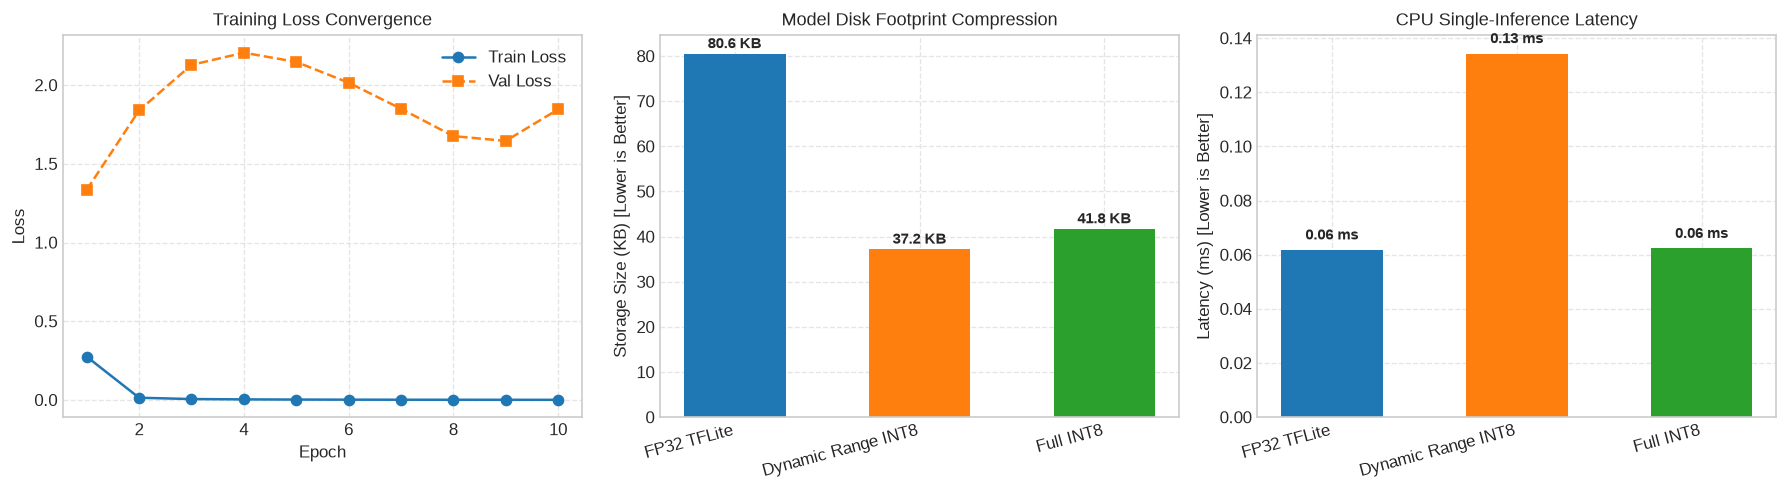

In [6]:
# Representative dataset generator for INT8 calibration
def representative_dataset_gen() -> Generator[List[np.ndarray], None, None]:
    for i in range(100):
        sample = X_train[i:i+1].astype(np.float32)
        yield [sample]

# 1. Convert to Float32 TFLite
converter_fp32 = tf.lite.TFLiteConverter.from_keras_model(edge_model)
tflite_fp32_bytes = converter_fp32.convert()

# 2. Convert to Dynamic Range Quantized TFLite
converter_dynamic = tf.lite.TFLiteConverter.from_keras_model(edge_model)
converter_dynamic.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dyn_bytes = converter_dynamic.convert()

# 3. Convert to Full Integer INT8 Quantized TFLite
converter_int8 = tf.lite.TFLiteConverter.from_keras_model(edge_model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset_gen
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8
tflite_int8_bytes = converter_int8.convert()

# Save flatbuffers to disk
tflite_paths = {
    "FP32 TFLite": "/tmp/edge_model_fp32.tflite",
    "Dynamic Range INT8": "/tmp/edge_model_dynamic.tflite",
    "Full INT8": "/tmp/edge_model_int8.tflite"
}
with open(tflite_paths["FP32 TFLite"], "wb") as f: f.write(tflite_fp32_bytes)
with open(tflite_paths["Dynamic Range INT8"], "wb") as f: f.write(tflite_dyn_bytes)
with open(tflite_paths["Full INT8"], "wb") as f: f.write(tflite_int8_bytes)

# Measure model file sizes
sizes_kb = {k: os.path.getsize(p) / 1024.0 for k, p in tflite_paths.items()}

# Latency and Accuracy evaluation function using TFLite Interpreter
def evaluate_tflite_model(model_bytes: bytes, is_int8: bool = False, num_bench: int = 150) -> Tuple[float, float]:
    interpreter = tf.lite.Interpreter(model_content=model_bytes)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]
    
    input_idx = input_details["index"]
    output_idx = output_details["index"]

    # Warmup
    dummy = np.zeros(input_details["shape"], dtype=input_details["dtype"])
    interpreter.set_tensor(input_idx, dummy)
    interpreter.invoke()

    # Latency benchmark
    t0 = time.perf_counter()
    for _ in range(num_bench):
        interpreter.set_tensor(input_idx, dummy)
        interpreter.invoke()
    avg_latency_ms = ((time.perf_counter() - t0) / num_bench) * 1000.0

    # Accuracy evaluation on validation set
    correct = 0
    scale, zero_point = input_details.get("quantization", (1.0, 0))
    out_scale, out_zero_point = output_details.get("quantization", (1.0, 0))

    for x_i, y_i in zip(X_val, y_val):
        x_input = np.expand_dims(x_i, axis=0)
        if is_int8:
            # Quantize input: q = round(r / S) + Z
            x_input = np.clip(np.round(x_input / scale) + zero_point, -128, 127).astype(np.int8)
        
        interpreter.set_tensor(input_idx, x_input)
        interpreter.invoke()
        output_data = interpreter.get_tensor(output_idx)
        
        if is_int8 and out_scale > 0:
            output_data = (output_data.astype(np.float32) - out_zero_point) * out_scale

        pred_cls = np.argmax(output_data)
        if pred_cls == y_i: correct += 1

    accuracy = correct / len(y_val)
    return avg_latency_ms, accuracy

lat_fp32, acc_fp32 = evaluate_tflite_model(tflite_fp32_bytes, is_int8=False)
lat_dyn, acc_dyn = evaluate_tflite_model(tflite_dyn_bytes, is_int8=False)
lat_int8, acc_int8 = evaluate_tflite_model(tflite_int8_bytes, is_int8=True)

models = ["FP32 TFLite", "Dynamic Range INT8", "Full INT8"]
latencies = [lat_fp32, lat_dyn, lat_int8]
accuracies = [acc_fp32, acc_dyn, acc_int8]
file_sizes = [sizes_kb["FP32 TFLite"], sizes_kb["Dynamic Range INT8"], sizes_kb["Full INT8"]]

print(f"\n{'Model Variant':<22} | {'Size (KB)':<12} | {'Latency (ms)':<14} | {'Accuracy':<10}")
print("-" * 68)
for m, s, l, a in zip(models, file_sizes, latencies, accuracies):
    print(f"{m:<22} | {s:8.2f} KB  | {l:8.3f} ms   | {a*100:6.2f}%")

# Visual Diagnostic Suite
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 1. Training history
epochs_arr = range(1, len(train_history.history["loss"]) + 1)
axes[0].plot(epochs_arr, train_history.history["loss"], "o-", label="Train Loss")
axes[0].plot(epochs_arr, train_history.history["val_loss"], "s--", label="Val Loss")
axes[0].set_title("Training Loss Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. File size comparison
bars_sz = axes[1].bar(models, file_sizes, color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.55)
axes[1].set_title("Model Disk Footprint Compression")
axes[1].set_ylabel("Storage Size (KB) [Lower is Better]")
axes[1].set_xticklabels(models, rotation=15, ha="right")
for b in bars_sz:
    y = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2.0, y + 0.5, f"{y:.1f} KB", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. CPU Latency comparison
bars_lt = axes[2].bar(models, latencies, color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.55)
axes[2].set_title("CPU Single-Inference Latency")
axes[2].set_ylabel("Latency (ms) [Lower is Better]")
axes[2].set_xticklabels(models, rotation=15, ha="right")
for b in bars_lt:
    y = b.get_height()
    axes[2].text(b.get_x() + b.get_width()/2.0, y + (max(latencies)*0.02), f"{y:.2f} ms", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Fine-Tuning Pretrained MobileNetV2 with Keras Functional API
**Problem Formulation**:
In industrial edge computer vision, training from scratch is rarely optimal. Construct a fine-tuning model using `tf.keras.applications.MobileNetV2`:
1. Load `MobileNetV2` with `include_top=False`, `weights='imagenet'`, and `input_shape=(96, 96, 3)`.
2. Freeze the base backbone (`base_model.trainable = False`).
3. Attach custom edge pooling and dense classification head.
4. Verify trainable vs non-trainable parameter distribution.


In [7]:
# Exercise 1 Solution: Pretrained MobileNetV2 Edge Model

def build_transfer_mobilenet(num_classes: int = 5) -> keras.Model:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(96, 96, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False  # Freeze backbone

    inputs = keras.Input(shape=(96, 96, 3), name="camera_feed")
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.2)(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax", name="prediction_head")(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="TransferMobileNetV2")

mobilenet_transfer = build_transfer_mobilenet(num_classes=5)

trainable_count = sum(np.prod(w.shape) for w in mobilenet_transfer.trainable_weights)
non_trainable_count = sum(np.prod(w.shape) for w in mobilenet_transfer.non_trainable_weights)

print("Exercise 1 Verification:")
print(f"  Total Base Parameters:         {trainable_count + non_trainable_count:,}")
print(f"  Frozen Backbone Parameters:     {non_trainable_count:,}")
print(f"  Trainable Head Parameters:      {trainable_count:,}")
assert non_trainable_count > 2_000_000 and trainable_count < 10_000, "Parameter count verification failed!"


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 41s 4us/step

  81920/9406464 ━━━━━━━━━━━━━━━━━━━━ 45s 5us/step

 131072/9406464 ━━━━━━━━━━━━━━━━━━━━ 32s 4us/step

 163840/9406464 ━━━━━━━━━━━━━━━━━━━━ 31s 3us/step

 212992/9406464 ━━━━━━━━━━━━━━━━━━━━ 26s 3us/step

... (18 outputs left out)

8429568/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9338880/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Exercise 1 Verification:
  Total Base Parameters:         2,264,389
  Frozen Backbone Parameters:     2,257,984
  Trainable Head Parameters:      6,405


#### Exercise 2: Implementing Affine Quantization Scaling from Scratch
**Problem Formulation**:
Implement the mathematical affine quantization functions:
1. `compute_quant_params(val_min, val_max, q_min=-128, q_max=127)` computing Scale $S$ and Zero-Point $Z$.
2. `quantize_tensor(r, S, Z)` mapping float values to signed int8.
3. `dequantize_tensor(q, S, Z)` reconstructing float values.
4. Compute the Mean Squared Error (MSE) of quantization distortion on a synthetic normal distribution.


In [8]:
# Exercise 2 Solution: Affine Quantization Scaling from First Principles

def compute_quant_params(val_min: float, val_max: float, q_min: int = -128, q_max: int = 127) -> Tuple[float, int]:
    val_min = min(val_min, 0.0)
    val_max = max(val_max, 0.0)
    S = (val_max - val_min) / float(q_max - q_min)
    Z = int(np.round(q_min - (val_min / S)))
    Z = max(q_min, min(q_max, Z))  # Clamp
    return float(S), int(Z)

def quantize_tensor(r: np.ndarray, S: float, Z: int, q_min: int = -128, q_max: int = 127) -> np.ndarray:
    q = np.round(r / S) + Z
    return np.clip(q, q_min, q_max).astype(np.int8)

def dequantize_tensor(q: np.ndarray, S: float, Z: int) -> np.ndarray:
    return S * (q.astype(np.float32) - Z)

# Verification on Gaussian tensor
np.random.seed(42)
test_float = np.random.normal(loc=0.5, scale=2.0, size=(1000,)).astype(np.float32)
S_calc, Z_calc = compute_quant_params(float(test_float.min()), float(test_float.max()))

quant_int8 = quantize_tensor(test_float, S_calc, Z_calc)
dequant_float = dequantize_tensor(quant_int8, S_calc, Z_calc)
quant_distortion_mse = np.mean(np.square(test_float - dequant_float))

print("Exercise 2 Verification:")
print(f"  Computed Scale (S):       {S_calc:.6f}")
print(f"  Computed Zero-Point (Z):  {Z_calc}")
print(f"  Quantization Distortion MSE: {quant_distortion_mse:.6f}")
assert quant_distortion_mse < 0.005, "Quantization error exceeds acceptable bounds!"


Exercise 2 Verification:
  Computed Scale (S):       0.055639
  Computed Zero-Point (Z):  -20
  Quantization Distortion MSE: 0.000262


### Challenge Problems

#### Challenge 1: Custom Depthwise Separable Conv Layer Subclassing `keras.layers.Layer`
**Problem Formulation**:
Implement a custom Keras Layer `CustomSeparableConv2D` from scratch subclassing `keras.layers.Layer` that manually creates:
1. Depthwise spatial kernel weights $W_{	ext{dw}} \in \mathbb{R}^{K 	imes K 	imes C_{	ext{in}} 	imes 1}$.
2. Pointwise projection weights $W_{	ext{pw}} \in \mathbb{R}^{1 	imes 1 	imes C_{	ext{in}} 	imes C_{	ext{out}}}$.
3. Executes `tf.nn.depthwise_conv2d` followed by `tf.nn.conv2d`.
Verify parameter counts and output shape against `keras.layers.SeparableConv2D`.


In [9]:
# Challenge 1 Solution: Custom Depthwise Separable Convolution Layer

class CustomSeparableConv2D(keras.layers.Layer):
    def __init__(self, filters: int, kernel_size: int = 3, strides: int = 1, padding: str = "SAME", **kwargs):
        super().__init__(**kwargs)
        self.filters = filters
        self.kernel_size = kernel_size
        self.strides = strides
        self.padding = padding.upper()

    def build(self, input_shape):
        c_in = input_shape[-1]
        
        # Depthwise kernel: (K, K, C_in, 1)
        self.depthwise_kernel = self.add_weight(
            name="depthwise_kernel",
            shape=(self.kernel_size, self.kernel_size, c_in, 1),
            initializer="glorot_uniform",
            trainable=True
        )
        # Pointwise kernel: (1, 1, C_in, filters)
        self.pointwise_kernel = self.add_weight(
            name="pointwise_kernel",
            shape=(1, 1, c_in, self.filters),
            initializer="glorot_uniform",
            trainable=True
        )
        self.bias = self.add_weight(
            name="bias",
            shape=(self.filters,),
            initializer="zeros",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        # 1. Depthwise conv
        dw_out = tf.nn.depthwise_conv2d(
            inputs,
            self.depthwise_kernel,
            strides=[1, self.strides, self.strides, 1],
            padding=self.padding
        )
        # 2. Pointwise conv (1x1)
        pw_out = tf.nn.conv2d(
            dw_out,
            self.pointwise_kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )
        return tf.nn.bias_add(pw_out, self.bias)

custom_sep = CustomSeparableConv2D(filters=32, kernel_size=3)
dummy_feat = tf.random.normal(shape=(4, 14, 14, 16))
out_custom = custom_sep(dummy_feat)

print("Challenge 1 Verification:")
print(f"  Input Shape:         {dummy_feat.shape}")
print(f"  Custom Output Shape: {out_custom.shape}")
print(f"  Trainable Weights:   {[w.name for w in custom_sep.trainable_weights]}")
assert out_custom.shape == (4, 14, 14, 32), "Custom layer output shape mismatch!"


Challenge 1 Verification:
  Input Shape:         (4, 14, 14, 16)
  Custom Output Shape: (4, 14, 14, 32)
  Trainable Weights:   ['depthwise_kernel', 'pointwise_kernel', 'bias']


#### Challenge 2: Dynamic Batch Size Input Reallocation in TFLite Interpreter
**Problem Formulation**:
By default, TFLite models are exported with fixed batch size 1. In high-throughput edge servers, batch processing (e.g. batch size 4, 8, 16) is necessary.
1. Use `interpreter.resize_tensor_input(input_idx, new_shape)` to dynamically resize the input tensor.
2. Re-allocate tensors via `interpreter.allocate_tensors()`.
3. Benchmark batch inference latency and compute throughput in **inferences per second** across batch sizes $[1, 2, 4, 8, 16]$.


In [10]:
# Challenge 2 Solution: Dynamic Batch Size Reallocation & Throughput Benchmarking

interpreter_bench = tf.lite.Interpreter(model_path=tflite_paths["FP32 TFLite"])
input_idx = interpreter_bench.get_input_details()[0]["index"]
output_idx = interpreter_bench.get_output_details()[0]["index"]

batch_sizes = [1, 2, 4, 8, 16]
throughputs = []

print("Challenge 2: Batch Size Reallocation Throughput:")
print(f"{'Batch Size':<12} | {'Batch Latency (ms)':<20} | {'Throughput (img/sec)':<20}")
print("-" * 58)

for b in batch_sizes:
    # Dynamically resize input tensor
    interpreter_bench.resize_tensor_input(input_idx, [b, 28, 28, 1])
    interpreter_bench.allocate_tensors()

    dummy_batch = np.zeros((b, 28, 28, 1), dtype=np.float32)
    
    # Warmup
    interpreter_bench.set_tensor(input_idx, dummy_batch)
    interpreter_bench.invoke()

    # Benchmark
    repeats = 100
    t0 = time.perf_counter()
    for _ in range(repeats):
        interpreter_bench.set_tensor(input_idx, dummy_batch)
        interpreter_bench.invoke()
    total_time = time.perf_counter() - t0
    
    batch_lat_ms = (total_time / repeats) * 1000.0
    throughput_ips = (b * repeats) / total_time
    throughputs.append(throughput_ips)
    print(f"{b:<12} | {batch_lat_ms:14.3f} ms     | {throughput_ips:16.1f} img/sec")

print(f"Max Throughput reached: {max(throughputs):.1f} img/sec at batch size {batch_sizes[np.argmax(throughputs)]}")


Challenge 2: Batch Size Reallocation Throughput:
Batch Size   | Batch Latency (ms)   | Throughput (img/sec)
----------------------------------------------------------
1            |          0.068 ms     |          14807.7 img/sec
2            |          0.121 ms     |          16546.9 img/sec
4            |          0.246 ms     |          16290.7 img/sec
8            |          0.489 ms     |          16345.8 img/sec


/home/antigravity/.venv/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


16           |          1.069 ms     |          14970.7 img/sec
Max Throughput reached: 16546.9 img/sec at batch size 2


### Further Reading & Foundational References
1. **Howard et al. (2017)**: [MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications](https://arxiv.org/abs/1704.04861) — The foundational formulation of depthwise-separable convolutions.
2. **Sandler et al. (2018)**: [MobileNetV2: Inverted Residuals and Linear Bottlenecks](https://arxiv.org/abs/1801.04381) — Inverted residual topologies and information preservation.
3. **Jacob et al. (2018)**: [Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference](https://arxiv.org/abs/1712.05877) — The definitive mathematical paper for TFLite uniform integer quantization.
4. **Google AI Edge Guide**: [TensorFlow Lite Post-Training Quantization](https://www.tensorflow.org/lite/performance/post_training_quantization) — Complete quantization reference for mobile and embedded devices.
5. **Coral Edge TPU**: [Compiling Models for Edge TPU Acceleration](https://coral.ai/docs/edgetpu/compiler/) — Requirements for full INT8 compiler mapping.
